# Number needed to treat (NNT)

This notebook calculates the number needed to treat (NNT) to avert one case of
Alzheimer's dementia. It uses the existing observers in the model 14.0 run.

**Definition.** NNT = 1 / ARR. ARR is the absolute risk reduction:

ARR = (Ctrl_Case − Trt_Case) / Trt_Pop

- **Trt_Pop:** medication initiations in the treatment scenario.
- **Trt_Case:** MCI to AD dementia transitions among simulants who started
  treatment, in the treatment scenario.
- **Ctrl_Case:** the same transitions among the same simulants, in the matched
  zero-impact treatment scenario. In that scenario, simulants start treatment,
  but the treatment has no effect.

A case counts as averted if it does not happen within the time horizon. This
includes cases that happen after the horizon and simulants who die first.

**Two methods.**

- **Method A (calendar window).** Sum initiations and averted cases over a
  window of calendar years, and divide. In equilibrium, this ratio estimates the
  long-run cases averted per initiation. It does not depend on the window
  length, so it does not give a 5-year or 10-year NNT.
- **Method B (cohort curve).** Treatment starts in 2028, and initiations grow
  over the following years. So averted cases in each calendar year are a known
  mix of earlier initiation cohorts. We solve for the cases averted per
  initiation by years since initiation, and then sum that curve to the horizon.

**Data sources (model 14.0).**

| Quantity | Observer | Filter |
|---|---|---|
| Trt_Pop | `transition_count_treatment` | `sub_entity == 'waiting_for_treatment_to_treatment_effect'` |
| Trt_Case, Ctrl_Case | `transition_count_alzheimers_disease_and_other_dementias` | `sub_entity` is MCI to AD dementia, and `treatment` is an ever-initiated state |

The ever-initiated treatment states are `treatment_effect`, `waning_effect`,
and `no_effect_after_treatment`. Cases in `waiting_for_treatment` happen before
initiation, so this notebook does not count them.

**Uncertainty.** We sum over random seeds, age groups, and sexes within each
draw. We calculate ARR for each draw and summarize it across draws with the
mean and the 2.5th and 97.5th percentiles. We then invert the ARR summary to
get NNT. The lower NNT bound comes from the upper ARR bound. We do not take
quantiles of NNT for each draw, because NNT is unstable when ARR is near zero.

In [1]:
import numpy as np
import pandas as pd
import pyarrow.dataset as ds
import matplotlib.pyplot as plt
from pathlib import Path

pd.set_option('display.width', 250)
pd.set_option('display.max_columns', 50)
pd.set_option('display.max_rows', 200)

!date
!whoami

Tue Nov 10 07:49:58 PST 2026
lutzes


## Settings

In [2]:
# Model 14.0 run (5 seeds of 20,000 simulants, 25 draws, 10 locations)
run_dir = Path('/mnt/team/simulation_science/pub/models/vivarium_csu_alzheimers'
               '/results/model14.0/model_spec/2026_10_30_13_30_29')
results_dir = run_dir / 'results'

# Each testing scenario has a matched zero-impact treatment scenario
SCENARIO_PAIRS = {
    'Slow': ('slow_testing_with_treatment',
             'slow_testing_zero_impact_treatment'),
    'Intermediate': ('intermediate_testing_with_treatment',
                     'intermediate_testing_zero_impact_treatment'),
    'Accelerated': ('accelerated_testing_with_treatment',
                    'accelerated_testing_zero_impact_treatment'),
}

INITIATION_TRANSITION = 'waiting_for_treatment_to_treatment_effect'
DEMENTIA_TRANSITION = ('alzheimers_mild_cognitive_impairment_state'
                       '_to_alzheimers_disease_state')
EVER_INITIATED_STATES = [
    'treatment_effect', 'waning_effect', 'no_effect_after_treatment']

# First year of treatment in all scenarios
TREATMENT_START_YEAR = 2028
LAST_YEAR = 2100

# Method A: calendar windows as (first year, length in years)
METHOD_A_WINDOWS = [(2050, 5), (2050, 10), (2060, 5), (2060, 10)]

# Method B: time horizons in years since initiation
HORIZONS = [5, 10]

## Load data

We read only the columns and rows that we need, and then sum over random seeds,
age groups, and sexes. The location comes from the artifact path.

In [3]:
LOCATION_NAMES = {
    'united_states_of_america': 'United States of America',
    'united_kingdom': 'United Kingdom',
}


def location_from_artifact_path(path):
    stem = Path(path).stem
    return LOCATION_NAMES.get(stem, stem.replace('_', ' ').title())


def load_counts(measure, sub_entity, extra_columns=()):
    # Load one observer, filter to one sub_entity, and sum over seeds, age
    # groups, and sexes.
    columns = ['artifact_path', 'scenario', 'input_draw', 'event_year',
               *extra_columns, 'value']
    dataset = ds.dataset(results_dir / measure, format='parquet')
    table = dataset.to_table(columns=columns,
                             filter=ds.field('sub_entity') == sub_entity)
    df = table.to_pandas()
    for col in ['artifact_path', 'scenario', *extra_columns]:
        df[col] = df[col].astype(str)
    df['location'] = df['artifact_path'].map(location_from_artifact_path)
    df['event_year'] = df['event_year'].astype(int)
    group_cols = ['location', 'scenario', 'input_draw', 'event_year',
                  *extra_columns]
    return df.groupby(group_cols, observed=True)['value'].sum().reset_index()


initiations_raw = load_counts('transition_count_treatment',
                              INITIATION_TRANSITION)
dementia_raw = load_counts(
    'transition_count_alzheimers_disease_and_other_dementias',
    DEMENTIA_TRANSITION, extra_columns=['treatment'])

print(len(initiations_raw), 'initiation rows')
print(len(dementia_raw), 'dementia transition rows')
LOCATIONS = sorted(initiations_raw['location'].unique())
DRAWS = sorted(initiations_raw['input_draw'].unique())
print(len(LOCATIONS), 'locations:', LOCATIONS)
print(len(DRAWS), 'draws')

138250 initiation rows
829500 dementia transition rows
10 locations: ['Brazil', 'China', 'Germany', 'Israel', 'Japan', 'Spain', 'Sweden', 'Taiwan', 'United Kingdom', 'United States of America']
25 draws


In [4]:
# Dementia cases by treatment state, all scenarios. Cases in
# waiting_for_treatment happen before initiation and we exclude them.
dementia_raw.groupby('treatment')['value'].sum()

treatment
no_effect_after_treatment    8.011073e+06
no_effect_never_treated      8.649084e+07
susceptible_to_treatment     1.433639e+09
treatment_effect             3.908321e+07
waiting_for_treatment        1.731200e+04
waning_effect                4.835658e+07
Name: value, dtype: float64

## Build one table of initiations and cases

One row per location, scenario pair, draw, and year. Columns:

- `trt_pop`: initiations in the treatment scenario
- `ctrl_pop`: initiations in the zero-impact scenario
- `trt_case`: cases among ever-initiated simulants in the treatment scenario
- `ctrl_case`: the same cases in the zero-impact scenario
- `averted`: `ctrl_case − trt_case`

In [5]:
cases_ever_initiated = (
    dementia_raw[dementia_raw['treatment'].isin(EVER_INITIATED_STATES)]
    .groupby(['location', 'scenario', 'input_draw', 'event_year'])['value']
    .sum()
)
initiations = (
    initiations_raw
    .set_index(['location', 'scenario', 'input_draw', 'event_year'])['value']
)

# Full index, so that years with no events have a zero
years = np.arange(TREATMENT_START_YEAR, LAST_YEAR + 1)
full_index = pd.MultiIndex.from_product(
    [LOCATIONS, DRAWS, years], names=['location', 'input_draw', 'event_year'])


def get_series(series, scenario):
    return (series.xs(scenario, level='scenario')
            .reindex(full_index, fill_value=0.0))


pieces = []
for pair_name, (trt_scenario, ctrl_scenario) in SCENARIO_PAIRS.items():
    piece = pd.DataFrame({
        'trt_pop': get_series(initiations, trt_scenario),
        'ctrl_pop': get_series(initiations, ctrl_scenario),
        'trt_case': get_series(cases_ever_initiated, trt_scenario),
        'ctrl_case': get_series(cases_ever_initiated, ctrl_scenario),
    })
    piece['scenario'] = pair_name
    pieces.append(piece)

nnt_data = (pd.concat(pieces).reset_index()
            .set_index(['location', 'scenario', 'input_draw', 'event_year'])
            .sort_index())
nnt_data['averted'] = nnt_data['ctrl_case'] - nnt_data['trt_case']
nnt_data

trt_pop  ctrl_pop  trt_case  ctrl_case  averted
location                 scenario    input_draw event_year                                                 
Brazil                   Accelerated 11         2028          193.0     193.0       0.0        0.0      0.0
                                                2029          293.0     293.0       3.0        5.0      2.0
                                                2030          396.0     396.0      16.0       25.0      9.0
                                                2031          512.0     512.0      36.0       43.0      7.0
                                                2032          642.0     642.0      61.0       80.0     19.0
...                                                             ...       ...       ...        ...      ...
United States of America Slow        243        2096         1942.0    1942.0    1052.0     1234.0    182.0
                                                2097         1908.0    1908.0    1003.0     1250.0    247.0
                                                2098         1893.0    1893.0    1053.0     1291.0    238.0
                                                2099         1930.0    1930.0    1093.0     1318.0    225.0
                                                2100         1958.0    1958.0    1062.0     1317.0    255.0

[54750 rows x 5 columns]

### Check: Ctrl_Pop equals Trt_Pop

The same simulants must start treatment in the treatment scenario and in the
zero-impact scenario. The initiation counts should match exactly in every
location, draw, and year.

In [6]:
max_diff = (nnt_data['trt_pop'] - nnt_data['ctrl_pop']).abs().max()
print('Largest difference in initiations:', max_diff)
assert max_diff == 0, 'Initiations differ between matched scenarios'

# Method B needs all initiations to happen in or after the treatment start
# year
early = initiations_raw.query('event_year < @TREATMENT_START_YEAR')['value'].sum()
print('Initiations before', TREATMENT_START_YEAR, ':', early)
assert early == 0, 'Initiations happen before the treatment start year'

Largest difference in initiations: 0.0
Initiations before 2028 : 0.0


### Initiations over time

Method A assumes equilibrium, with a stable number of initiations each year.
This table shows the yearly growth in initiations after 2050, summed over draws.

In [7]:
yearly_init = (nnt_data.groupby(['location', 'scenario', 'event_year'])['trt_pop']
               .sum().unstack('event_year'))
growth = pd.DataFrame({
    'initiations 2050': yearly_init[2050],
    'initiations 2075': yearly_init[2075],
    'mean yearly growth 2050-2075 (%)':
        100 * ((yearly_init[2075] / yearly_init[2050]) ** (1 / 25) - 1),
}).round(2)
growth.xs('Intermediate', level='scenario')

,initiations 2050,initiations 2075,mean yearly growth 2050-2075 (%)
location,,,
Brazil,49374.0,72233.0,1.53
China,49184.0,65877.0,1.18
Germany,21156.0,29170.0,1.29
Israel,41433.0,59957.0,1.49
Japan,17790.0,23577.0,1.13
Spain,30228.0,41266.0,1.25
Sweden,26071.0,36925.0,1.40
Taiwan,37667.0,52650.0,1.35
United Kingdom,29307.0,40978.0,1.35


## Summary function

In [8]:
def summarize_arr(arr_by_draw, group_cols):
    # Summarize ARR across draws, then invert to get NNT. The lower NNT bound
    # comes from the upper ARR bound. If the lower ARR bound is zero or less,
    # the upper NNT bound is infinite.
    grouped = arr_by_draw.groupby(group_cols)
    summary = pd.DataFrame({
        'arr_mean': grouped.mean(),
        'arr_lower': grouped.quantile(0.025),
        'arr_upper': grouped.quantile(0.975),
    })
    summary['nnt'] = 1 / summary['arr_mean']
    summary['nnt_lower'] = 1 / summary['arr_upper']
    summary['nnt_upper'] = np.where(
        summary['arr_lower'] > 0, 1 / summary['arr_lower'], np.inf)
    return summary


def nnt_table(summary, column_level):
    # Format NNT as 'mean (lower, upper)' with one column per value of
    # column_level
    def fmt(row):
        upper = ('inf' if np.isinf(row['nnt_upper'])
                 else f"{row['nnt_upper']:.1f}")
        return f"{row['nnt']:.1f} ({row['nnt_lower']:.1f}, {upper})"
    return summary.apply(fmt, axis=1).unstack(column_level)

## Method A: calendar window

For a window from year $Y_0$ to $Y_0 + L - 1$:

$$\text{ARR}_A = \frac{\sum_{Y} (\text{Ctrl\_Case}_Y - \text{Trt\_Case}_Y)}{\sum_{Y} \text{Trt\_Pop}_Y}$$

**Limitation.** Cases in the window can come from simulants who started
treatment before the window. Simulants who start treatment late in the window
have little follow-up. In equilibrium these two errors cancel, but the result
is the long-run cases averted per initiation, not a 5-year or 10-year value.
A delayed case that happens in the treatment scenario later still counts
against the treatment in a later year. So Method A counts mostly the cases
that never happen because the simulant dies first.

In [9]:
method_a_rows = []
for first_year, length in METHOD_A_WINDOWS:
    last_year = first_year + length - 1
    window = (nnt_data
              .query('@first_year <= event_year <= @last_year')
              .groupby(['location', 'scenario', 'input_draw'])
              [['trt_pop', 'averted']].sum())
    arr = (window['averted'] / window['trt_pop']).rename('arr').to_frame()
    arr['window'] = f'{first_year}-{last_year}'
    method_a_rows.append(arr)

method_a_arr = (pd.concat(method_a_rows)
                .set_index('window', append=True)['arr'])
method_a = summarize_arr(method_a_arr, ['location', 'scenario', 'window'])
method_a.round(4)

arr_mean  arr_lower  arr_upper      nnt  nnt_lower  nnt_upper
location                 scenario     window                                                                  
Brazil                   Accelerated  2050-2054    0.1053     0.0778     0.1396   9.4977     7.1621    12.8453
                                      2050-2059    0.1046     0.0809     0.1322   9.5630     7.5640    12.3610
                                      2060-2064    0.1047     0.0813     0.1340   9.5546     7.4617    12.3065
                                      2060-2069    0.1024     0.0797     0.1301   9.7610     7.6838    12.5483
                         Intermediate 2050-2054    0.1121     0.0843     0.1452   8.9222     6.8875    11.8687
                                      2050-2059    0.1091     0.0844     0.1362   9.1693     7.3404    11.8423
                                      2060-2064    0.1052     0.0819     0.1343   9.5097     7.4486    12.2063
                                      2060-2069    0.1028     0.0800     0.1305   9.7320     7.6654    12.4964
                         Slow         2050-2054    0.1183     0.0916     0.1530   8.4567     6.5352    10.9215
                                      2050-2059    0.1156     0.0905     0.1437   8.6518     6.9605    11.0443
                                      2060-2064    0.1073     0.0837     0.1356   9.3196     7.3731    11.9416
                                      2060-2069    0.1039     0.0806     0.1311   9.6232     7.6302    12.4059
China                    Accelerated  2050-2054    0.1179     0.0897     0.1553   8.4847     6.4384    11.1435
                                      2050-2059    0.1112     0.0864     0.1421   8.9921     7.0381    11.5702
                                      2060-2064    0.1041     0.0790     0.1336   9.6033     7.4870    12.6596
                                      2060-2069    0.1043     0.0808     0.1324   9.5831     7.5525    12.3747
                         Intermediate 2050-2054    0.1250     0.0971     0.1613   8.0028     6.1985    10.2935
                                      2050-2059    0.1157     0.0907     0.1462   8.6446     6.8399    11.0306
                                      2060-2064    0.1046     0.0792     0.1342   9.5575     7.4499    12.6187
                                      2060-2069    0.1046     0.0808     0.1327   9.5582     7.5343    12.3802
                         Slow         2050-2054    0.1320     0.1042     0.1681   7.5778     5.9476     9.5928
                                      2050-2059    0.1228     0.0964     0.1534   8.1441     6.5183    10.3764
                                      2060-2064    0.1066     0.0809     0.1365   9.3773     7.3252    12.3663
                                      2060-2069    0.1057     0.0813     0.1338   9.4583     7.4759    12.2927
Germany                  Accelerated  2050-2054    0.1155     0.0853     0.1555   8.6593     6.4292    11.7210
                                      2050-2059    0.1095     0.0834     0.1356   9.1292     7.3727    11.9965
                                      2060-2064    0.1053     0.0788     0.1371   9.4953     7.2957    12.6940
                                      2060-2069    0.1062     0.0825     0.1328   9.4146     7.5291    12.1226
                         Intermediate 2050-2054    0.1250     0.0898     0.1595   7.9987     6.2706    11.1341
                                      2050-2059    0.1152     0.0859     0.1402   8.6773     7.1321    11.6369
                                      2060-2064    0.1059     0.0798     0.1382   9.4467     7.2378    12.5353
                                      2060-2069    0.1065     0.0831     0.1332   9.3878     7.5094    12.0355
                         Slow         2050-2054    0.1324     0.0989     0.1683   7.5551     5.9431    10.1148
                                      2050-2059    0.1230     0.0927     0.1501   8.1279     6.6611    10.7831
                                      2060-2064    0.

### Method A: NNT, mean (95% UI)

In [10]:
nnt_table(method_a, 'window')

window                                       2050-2054        2050-2059         2060-2064         2060-2069
location                 scenario                                                                          
Brazil                   Accelerated   9.5 (7.2, 12.8)  9.6 (7.6, 12.4)   9.6 (7.5, 12.3)   9.8 (7.7, 12.5)
                         Intermediate  8.9 (6.9, 11.9)  9.2 (7.3, 11.8)   9.5 (7.4, 12.2)   9.7 (7.7, 12.5)
                         Slow          8.5 (6.5, 10.9)  8.7 (7.0, 11.0)   9.3 (7.4, 11.9)   9.6 (7.6, 12.4)
China                    Accelerated   8.5 (6.4, 11.1)  9.0 (7.0, 11.6)   9.6 (7.5, 12.7)   9.6 (7.6, 12.4)
                         Intermediate  8.0 (6.2, 10.3)  8.6 (6.8, 11.0)   9.6 (7.4, 12.6)   9.6 (7.5, 12.4)
                         Slow           7.6 (5.9, 9.6)  8.1 (6.5, 10.4)   9.4 (7.3, 12.4)   9.5 (7.5, 12.3)
Germany                  Accelerated   8.7 (6.4, 11.7)  9.1 (7.4, 12.0)   9.5 (7.3, 12.7)   9.4 (7.5, 12.1)
                         Intermediate  8.0 (6.3, 11.1)  8.7 (7.1, 11.6)   9.4 (7.2, 12.5)   9.4 (7.5, 12.0)
                         Slow          7.6 (5.9, 10.1)  8.1 (6.7, 10.8)   9.2 (7.2, 12.6)   9.3 (7.5, 12.0)
Israel                   Accelerated   9.2 (7.1, 12.2)  9.0 (7.3, 11.5)   9.0 (7.1, 11.9)   9.1 (7.3, 11.8)
                         Intermediate  8.6 (6.8, 11.7)  8.7 (7.1, 11.3)   9.0 (7.1, 11.8)   9.1 (7.3, 11.8)
                         Slow          8.3 (6.4, 10.8)  8.3 (6.8, 10.7)   8.8 (7.0, 11.7)   9.0 (7.2, 11.8)
Japan                    Accelerated   9.0 (6.9, 12.7)  9.4 (7.5, 12.5)  10.5 (7.7, 13.7)  10.5 (8.1, 13.7)
                         Intermediate  8.2 (6.4, 11.9)  8.8 (7.1, 12.0)  10.4 (7.6, 13.5)  10.4 (8.1, 13.7)
                         Slow          7.7 (6.0, 10.4)  8.1 (6.5, 10.9)  10.0 (7.5, 13.2)  10.2 (7.9, 13.7)
Spain                    Accelerated   8.7 (6.5, 11.8)  9.0 (7.2, 11.6)   9.5 (7.4, 12.5)   9.5 (7.5, 12.4)
                         Intermediate  8.1 (6.3, 11.1)  8.5 (7.0, 11.2)   9.4 (7.4, 12.4)   9.5 (7.5, 12.3)
                         Slow          7.7 (5.8, 10.2)  8.0 (6.5, 10.5)   9.2 (7.3, 12.2)   9.4 (7.5, 12.3)
Sweden                   Accelerated   8.8 (6.7, 12.2)  9.0 (7.4, 11.9)   9.2 (7.2, 11.8)   9.3 (7.4, 11.8)
                         Intermediate  8.2 (6.5, 11.6)  8.6 (7.1, 11.5)   9.1 (7.2, 11.8)   9.2 (7.4, 11.8)
                         Slow          7.8 (6.1, 10.6)  8.1 (6.7, 10.8)   9.0 (7.1, 11.7)   9.2 (7.4, 11.7)
Taiwan                   Accelerated   9.2 (6.9, 12.4)  9.4 (7.5, 12.1)   9.5 (7.5, 12.5)   9.6 (7.7, 12.4)
                         Intermediate  8.5 (6.5, 11.5)  8.9 (7.1, 11.5)   9.5 (7.4, 12.4)   9.6 (7.6, 12.4)
                         Slow          8.1 (6.2, 10.4)  8.4 (6.7, 10.6)   9.3 (7.3, 12.3)   9.5 (7.6, 12.3)
United Kingdom           Accelerated   8.8 (6.7, 11.7)  9.1 (7.4, 11.7)   9.3 (7.2, 12.3)   9.3 (7.5, 12.1)
                         Intermediate  8.2 (6.5, 11.1)  8.7 (7.1, 11.3)   9.3 (7.2, 12.3)   9.3 (7.5, 12.1)
                         Slow          7.8 (6.1, 10.2)  8.2 (6.7, 10.6)   9.1 (7.1, 12.2)   9.2 (7.4, 12.1)
United States of America Accelerated   9.2 (6.8, 12.8)  9.4 (7.5, 12.3)   9.3 (7.3, 12.2)   9.3 (7.5, 12.1)
                         Intermediate  8.6 (6.5, 11.9)  9.0 (7.3, 11.8)   9.3 (7.3, 12.1)   9.3 (7.5, 12.1)
                         Slow          8.1 (6.1, 10.9)  8.4 (6.8, 10.9)   9.1 (7.3, 12.2)   9.2 (7.4, 12.1)

## Method B: cohort curve

Let $a(t)$ be the cases averted per initiation, $t$ calendar years after the
year of initiation. If every initiation cohort has the same curve $a(t)$, then
for each calendar year $Y$:

$$\text{averted}(Y) = \sum_{y = 2028}^{Y} \text{Trt\_Pop}(y)\, a(Y - y)$$

Treatment starts in 2028, so this is a lower-triangular system of equations,
and we can solve it for $a(t)$. We do this for each location, scenario, and
draw. We also solve the three scenarios together with least squares, because
their initiation ramps differ, and this should make the estimate more stable.
After about 2060 the three scenarios have almost the same initiations, so most
of the extra information comes from the ramp-up years.

**From $a(t)$ to a horizon.** $t$ is a difference in calendar years, not exact
time. If initiations and cases are spread evenly within each year, then cases
at $t = H$ have an exact follow-up time between $H - 1$ and $H + 1$, centered
on $H$. So about half of them fall within $H$ years. The ARR for horizon $H$ is
about:

$$\text{ARR}_B(H) \approx \sum_{t=0}^{H-1} a(t) + \tfrac{1}{2} a(H)$$

We also report the two bounds, the sums to $t = H - 1$ and to $t = H$.

**Assumptions and limitations.**

1. Every initiation cohort has the same curve $a(t)$. If the testing ramp
   changes who starts treatment, for example by age or disease stage, this does
   not hold. A cohort calculation in the interactive simulation can test this.
2. Solving the system increases noise, especially for large $t$. The 5-year and
   10-year sums use only $a(0)$ to $a(10)$, which depend only on the years 2028
   to 2038.
3. The half-year adjustment assumes that $a(t)$ changes slowly near $t = H$.

In [11]:
N_YEARS = len(years)


def initiation_matrix(trt_pop):
    # M[Y, t] = Trt_Pop(Y - t) for t <= Y, so that averted = M @ a
    m = np.zeros((N_YEARS, N_YEARS))
    for row in range(N_YEARS):
        m[row, :row + 1] = trt_pop[row::-1]
    return m


def solve_cohort_curve(blocks):
    # blocks is a list of (trt_pop, averted) arrays, one per scenario. With
    # one block the system is square and lower triangular. With more than one
    # block we use least squares.
    m = np.vstack([initiation_matrix(p) for p, _ in blocks])
    b = np.concatenate([a for _, a in blocks])
    if len(blocks) == 1:
        return np.linalg.solve(m, b)
    return np.linalg.lstsq(m, b, rcond=None)[0]


curve_rows = []
for (location, draw), df in nnt_data.groupby(['location', 'input_draw']):
    blocks = {}
    for scenario, sdf in df.groupby('scenario'):
        sdf = sdf.droplevel(['location', 'scenario', 'input_draw']).sort_index()
        blocks[scenario] = (sdf['trt_pop'].to_numpy(),
                            sdf['averted'].to_numpy())
        curve = solve_cohort_curve([blocks[scenario]])
        curve_rows.append(pd.DataFrame({
            'location': location, 'scenario': scenario, 'input_draw': draw,
            't': np.arange(N_YEARS), 'a': curve}))
    curve = solve_cohort_curve(list(blocks.values()))
    curve_rows.append(pd.DataFrame({
        'location': location, 'scenario': 'Joint', 'input_draw': draw,
        't': np.arange(N_YEARS), 'a': curve}))

cohort_curves = (pd.concat(curve_rows)
                 .set_index(['location', 'scenario', 'input_draw', 't'])['a']
                 .sort_index())
cohort_curves.unstack('t').iloc[:, :12].round(4).head(10)

t                                 0       1       2       3       4       5       6       7       8       9       10      11
location scenario    input_draw                                                                                             
Brazil   Accelerated 11          0.0  0.0104  0.0309 -0.0319  0.0560  0.0298  0.0217  0.0026  0.0768 -0.0458  0.0007  0.0205
                     15          0.0  0.0101  0.0102  0.0284  0.0385  0.0524  0.0411  0.0563 -0.1129  0.0852 -0.0980  0.1806
                     19          0.0 -0.0000  0.0479  0.0249 -0.0285  0.1319 -0.1665  0.1792  0.0066 -0.1357  0.1713  0.0125
                     24         -0.0  0.0055  0.0464 -0.0156  0.0280  0.1376 -0.0808  0.1032 -0.0947 -0.0016  0.0848  0.1786
                     26          0.0  0.0049  0.0119  0.0408  0.0091  0.0292  0.0065 -0.0190  0.1574 -0.1381  0.1279 -0.2296
                     35         -0.0  0.0000  0.0185  0.0525 -0.0146  0.0311  0.0585 -0.0705  0.0176  0.0542 -0.0473  0.1330
                     41         -0.0  0.0000  0.0331 -0.0162  0.0580  0.0216  0.0425 -0.0545  0.1117 -0.1000 -0.0147  0.1309
                     75          0.0  0.0090  0.0050  0.0355 -0.0112  0.0582  0.0318  0.0054 -0.0396  0.1632 -0.0714  0.0172
                     90         -0.0  0.0000  0.0118  0.0509  0.0068 -0.0130  0.0785  0.0164 -0.0284  0.0573 -0.0986  0.0886
                     96         -0.0  0.0123 -0.0060  0.0815 -0.1150  0.2359 -0.1627  0.2336 -0.2797  0.4046 -0.4314  0.3583

### Method B: ARR and NNT by horizon

In [12]:
cumulative = cohort_curves.groupby(
    ['location', 'scenario', 'input_draw']).cumsum()


def arr_at(level, t):
    return cumulative.xs(t, level='t').rename(level)


method_b_rows = []
for h in HORIZONS:
    lower = arr_at('lower', h - 1)
    upper = arr_at('upper', h)
    point = ((lower + upper) / 2).rename('arr')
    for kind, series in [('midpoint', point), ('sum to t = H-1', lower),
                         ('sum to t = H', upper)]:
        frame = series.rename('arr').to_frame()
        frame['horizon'] = f'{h} years'
        frame['estimate'] = kind
        method_b_rows.append(frame)

method_b_arr = (pd.concat(method_b_rows)
                .set_index(['horizon', 'estimate'], append=True)['arr'])
method_b = summarize_arr(
    method_b_arr, ['location', 'scenario', 'horizon', 'estimate'])
method_b.xs('midpoint', level='estimate').round(4)

arr_mean  arr_lower  arr_upper      nnt  nnt_lower  nnt_upper
location                 scenario     horizon                                                                
Brazil                   Accelerated  10 years    0.1576     0.1049     0.2379   6.3464     4.2043     9.5310
                                      5 years     0.0915     0.0578     0.1379  10.9273     7.2494    17.3123
                         Intermediate 10 years    0.1651     0.0607     0.2341   6.0565     4.2710    16.4866
                                      5 years     0.0898     0.0502     0.1406  11.1315     7.1149    19.9016
                         Joint        10 years    0.1637     0.1226     0.2256   6.1100     4.4332     8.1599
                                      5 years     0.0913     0.0493     0.1383  10.9477     7.2328    20.2660
                         Slow         10 years    0.1612     0.0867     0.2100   6.2051     4.7619    11.5329
                                      5 years     0.0912     0.0524     0.1335  10.9605     7.4931    19.0705
China                    Accelerated  10 years    0.1509     0.0981     0.2105   6.6278     4.7505    10.1987
                                      5 years     0.0929     0.0551     0.1310  10.7599     7.6333    18.1516
                         Intermediate 10 years    0.1576     0.0798     0.2052   6.3462     4.8727    12.5303
                                      5 years     0.0889     0.0397     0.1224  11.2493     8.1685    25.1771
                         Joint        10 years    0.1585     0.1109     0.2325   6.3082     4.3002     9.0156
                                      5 years     0.0896     0.0537     0.1245  11.1579     8.0317    18.6145
                         Slow         10 years    0.1562     0.0913     0.2204   6.4040     4.5364    10.9483
                                      5 years     0.0919     0.0572     0.1258  10.8838     7.9511    17.4730
Germany                  Accelerated  10 years    0.1592     0.0817     0.2485   6.2812     4.0243    12.2381
                                      5 years     0.0923     0.0494     0.1484  10.8333     6.7377    20.2292
                         Intermediate 10 years    0.1587     0.0467     0.2640   6.2995     3.7881    21.4160
                                      5 years     0.0820     0.0045     0.1408  12.1978     7.1027   220.9226
                         Joint        10 years    0.1596     0.1107     0.2001   6.2662     4.9980     9.0329
                                      5 years     0.0988     0.0473     0.1399  10.1201     7.1497    21.1351
                         Slow         10 years    0.1752     0.0882     0.2400   5.7085     4.1660    11.3344
                                      5 years     0.0902     0.0422     0.1483  11.0924     6.7419    23.7069
Israel                   Accelerated  10 years    0.1659     0.1154     0.2360   6.0285     4.2375     8.6670
                                      5 years     0.0931     0.0594     0.1350  10.7453     7.4087    16.8347
                         Intermediate 10 years    0.1656     0.0824     0.2448   6.0374     4.0852    12.1286
                                      5 years     0.0866     0.0393     0.1260  11.5458     7.9349    25.4383
                         Joint        10 years    0.1688     0.1097     0.2357   5.9235     4.2424     9.1148
                                      5 years     0.0977     0.0576     0.1361  10.2350     7.3475    17.3645
                         Slow         10 years    0.1724     0.1059     0.2382   5.8004     4.1979     9.4385
                                      5 years     0.0918     0.0527     0.1339  10.8974     7.4663    18.9879
Japan                    Accelerated  10 years    0.1620     0.0237     0.2987   6.1730     3.3481    42.1249
                                      5 years     0.0916     0.0426     0.1467  10.9121     6.8149    23.4895
                         Intermediate 10 years    0.1757     0.0612     0.2745   5.6928 

### Method B: NNT, mean (95% UI), midpoint estimate

The joint estimate uses all three scenarios together. In my judgment, it is the
estimate to report, unless the three single-scenario estimates disagree by more
than their uncertainty. Such a disagreement would suggest that the curve
$a(t)$ is not the same for every cohort.

In [13]:
nnt_table(method_b.xs('midpoint', level='estimate'), 'horizon')

horizon                                       10 years            5 years
location                 scenario                                        
Brazil                   Accelerated    6.3 (4.2, 9.5)   10.9 (7.2, 17.3)
                         Intermediate  6.1 (4.3, 16.5)   11.1 (7.1, 19.9)
                         Joint          6.1 (4.4, 8.2)   10.9 (7.2, 20.3)
                         Slow          6.2 (4.8, 11.5)   11.0 (7.5, 19.1)
China                    Accelerated   6.6 (4.8, 10.2)   10.8 (7.6, 18.2)
                         Intermediate  6.3 (4.9, 12.5)   11.2 (8.2, 25.2)
                         Joint          6.3 (4.3, 9.0)   11.2 (8.0, 18.6)
                         Slow          6.4 (4.5, 10.9)   10.9 (8.0, 17.5)
Germany                  Accelerated   6.3 (4.0, 12.2)   10.8 (6.7, 20.2)
                         Intermediate  6.3 (3.8, 21.4)  12.2 (7.1, 220.9)
                         Joint          6.3 (5.0, 9.0)   10.1 (7.1, 21.1)
                         Slow          5.7 (4.2, 11.3)   11.1 (6.7, 23.7)
Israel                   Accelerated    6.0 (4.2, 8.7)   10.7 (7.4, 16.8)
                         Intermediate  6.0 (4.1, 12.1)   11.5 (7.9, 25.4)
                         Joint          5.9 (4.2, 9.1)   10.2 (7.3, 17.4)
                         Slow           5.8 (4.2, 9.4)   10.9 (7.5, 19.0)
Japan                    Accelerated   6.2 (3.3, 42.1)   10.9 (6.8, 23.5)
                         Intermediate  5.7 (3.6, 16.3)  12.1 (6.6, 101.0)
                         Joint          5.6 (4.5, 7.8)   10.5 (6.8, 19.2)
                         Slow           5.1 (3.5, 9.2)   11.0 (6.6, 24.2)
Spain                    Accelerated   6.1 (4.3, 10.2)   10.7 (6.9, 18.5)
                         Intermediate  6.0 (3.9, 22.8)   11.4 (6.8, 55.1)
                         Joint          6.1 (4.6, 9.1)   10.4 (7.4, 19.7)
                         Slow           5.4 (3.9, 8.7)   11.0 (6.7, 22.2)
Sweden                   Accelerated   6.2 (4.3, 11.1)   10.7 (7.1, 19.9)
                         Intermediate  6.0 (3.7, 18.7)   11.7 (7.3, 46.1)
                         Joint          6.2 (4.4, 8.2)    9.8 (6.6, 18.7)
                         Slow          5.6 (3.7, 11.4)   10.8 (7.2, 19.9)
Taiwan                   Accelerated    6.1 (4.3, 9.2)   10.9 (7.8, 19.0)
                         Intermediate  6.1 (4.1, 14.2)   11.5 (7.1, 33.4)
                         Joint          6.1 (4.5, 8.2)   10.3 (7.5, 20.1)
                         Slow          5.9 (4.3, 11.8)   11.1 (7.4, 20.1)
United Kingdom           Accelerated   6.1 (4.2, 12.4)   10.8 (7.4, 19.0)
                         Intermediate  6.3 (4.1, 15.8)   11.4 (7.8, 32.1)
                         Joint          6.4 (4.6, 9.1)   10.4 (7.5, 27.2)
                         Slow          5.9 (4.5, 10.1)   11.3 (7.5, 18.6)
United States of America Accelerated    6.5 (4.5, 9.4)   10.8 (7.6, 19.2)
                         Intermediate  6.6 (4.5, 16.7)   11.3 (7.6, 28.0)
                         Joint          6.5 (4.8, 9.1)   10.1 (7.9, 20.8)
                         Slow           6.2 (4.5, 9.7)   11.1 (7.5, 18.9)

### Method B: bounds from the calendar-year offset (joint estimate)

In [14]:
nnt_table(method_b.xs('Joint', level='scenario'), 'estimate')

estimate                                   midpoint     sum to t = H      sum to t = H-1
location                 horizon                                                        
Brazil                   10 years    6.1 (4.4, 8.2)   6.0 (3.8, 9.2)     6.2 (3.8, 14.4)
                         5 years   10.9 (7.2, 20.3)  8.6 (5.3, 15.6)     15.1 (8.2, inf)
China                    10 years    6.3 (4.3, 9.0)   6.2 (3.6, 9.4)     6.4 (4.2, 11.7)
                         5 years   11.2 (8.0, 18.6)  9.7 (6.9, 14.7)    13.1 (8.3, 31.8)
Germany                  10 years    6.3 (5.0, 9.0)  6.0 (4.5, 10.0)     6.5 (4.7, 12.1)
                         5 years   10.1 (7.1, 21.1)  8.6 (5.8, 16.2)   12.4 (6.9, 233.6)
Israel                   10 years    5.9 (4.2, 9.1)   5.7 (3.7, 9.9)     6.1 (4.2, 11.1)
                         5 years   10.2 (7.3, 17.4)  8.6 (6.1, 14.6)    12.6 (7.1, 37.0)
Japan                    10 years    5.6 (4.5, 7.8)  5.8 (4.2, 10.0)     5.5 (4.0, 10.8)
                         5 years   10.5 (6.8, 19.2)  9.0 (6.2, 23.6)  12.7 (6.9, 2627.1)
Spain                    10 years    6.1 (4.6, 9.1)   5.8 (4.1, 9.9)     6.3 (4.3, 11.6)
                         5 years   10.4 (7.4, 19.7)  9.0 (6.9, 18.8)   12.2 (6.2, 221.4)
Sweden                   10 years    6.2 (4.4, 8.2)  5.9 (4.0, 11.0)     6.6 (4.4, 11.6)
                         5 years    9.8 (6.6, 18.7)  8.4 (6.1, 20.8)    11.7 (6.9, 79.4)
Taiwan                   10 years    6.1 (4.5, 8.2)   5.9 (3.9, 8.0)     6.3 (4.2, 10.1)
                         5 years   10.3 (7.5, 20.1)  8.4 (5.9, 13.5)     13.2 (8.6, inf)
United Kingdom           10 years    6.4 (4.6, 9.1)   6.2 (4.3, 9.2)     6.6 (4.6, 11.1)
                         5 years   10.4 (7.5, 27.2)  8.8 (6.1, 19.9)     12.6 (7.4, inf)
United States of America 10 years    6.5 (4.8, 9.1)   6.0 (4.2, 9.1)     6.9 (4.9, 10.7)
                         5 years   10.1 (7.9, 20.8)  8.8 (6.3, 21.7)    12.0 (7.5, 60.3)

## Comparison of the two methods

The cohort curve levels off after the delayed cases occur. Its long-run level
should match Method A. As a check, this table compares the joint Method B
cumulative sum, averaged over $t$ = 20 to 30, with Method A for 2060-2069.
Values for large $t$ are noisy, so this check is rough.

We use only the joint estimate here. The single-scenario solutions are not
stable for large $t$: each step of the triangular solve divides by the small
initiation count in 2028, so the noise grows with $t$. The single-scenario
values for $t$ up to 10 are usable but have wide uncertainty.

In [15]:
long_run_b = (cumulative.xs('Joint', level='scenario')
              .loc[(slice(None), slice(None), slice(20, 30))]
              .groupby(['location', 'input_draw']).mean())
long_run_b = summarize_arr(long_run_b, ['location'])
method_a_late = method_a.xs('2060-2069', level='window')
joint_b = method_b.xs(('Joint', 'midpoint'),
                      level=['scenario', 'estimate'])['arr_mean'].unstack('horizon')

comparison = pd.concat([
    method_a_late['arr_mean'].unstack('scenario')
        .add_prefix('Method A 2060-2069, '),
    long_run_b['arr_mean'].rename('Method B joint, long run'),
    joint_b.add_prefix('Method B joint, '),
], axis=1)
comparison.round(4)

,"Method A 2060-2069, Accelerated","Method A 2060-2069, Intermediate","Method A 2060-2069, Slow","Method B joint, long run","Method B joint, 10 years","Method B joint, 5 years"
location,,,,,,
Brazil,0.1024,0.1028,0.1039,0.0960,0.1637,0.0913
China,0.1043,0.1046,0.1057,0.1059,0.1585,0.0896
Germany,0.1062,0.1065,0.1076,0.1102,0.1596,0.0988
Israel,0.1096,0.1098,0.1108,0.1058,0.1688,0.0977
Japan,0.0954,0.0960,0.0978,0.0932,0.1772,0.0952
Spain,0.1049,0.1052,0.1064,0.1041,0.1652,0.0963
Sweden,0.1079,0.1081,0.1092,0.1086,0.1604,0.1025
Taiwan,0.1041,0.1044,0.1056,0.1041,0.1637,0.0974
United Kingdom,0.1072,0.1074,0.1085,0.1079,0.1575,0.0963


## Plot: cumulative cases averted per initiation (Method B, joint estimate)

The line is the mean across draws. The band is the 95% UI across draws. The
dashed line is the Method A ARR for 2060-2069 in the intermediate scenario. The
y-axis value at $t$ is 1/NNT for that horizon. The gray vertical lines mark
$t$ = 5 and $t$ = 10.

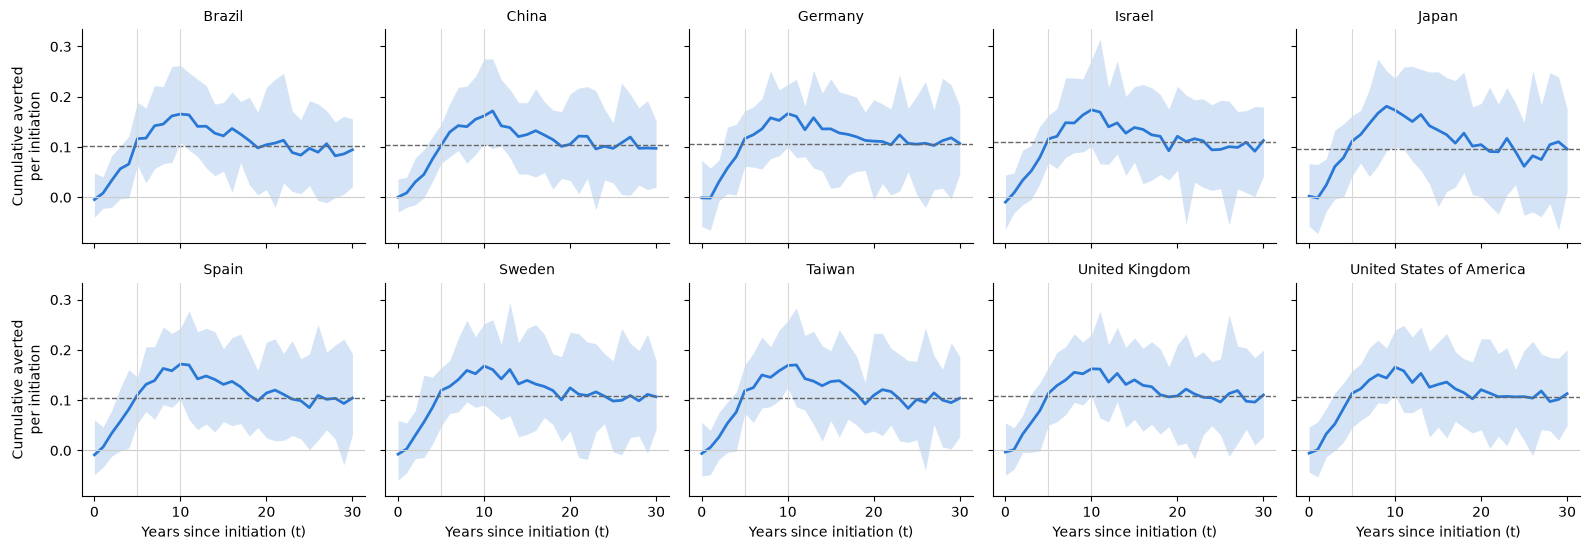

In [16]:
LINE_COLOR = '#2a78d6'
summary_curve = (cumulative.xs('Joint', level='scenario')
                 .groupby(['location', 't'])
                 .agg(mean='mean',
                      lower=lambda x: x.quantile(0.025),
                      upper=lambda x: x.quantile(0.975)))
T_MAX = 30

n_cols = 5
n_rows = int(np.ceil(len(LOCATIONS) / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(3.2 * n_cols, 2.8 * n_rows),
                         sharex=True, sharey=True)
for ax, location in zip(axes.flat, LOCATIONS):
    df = summary_curve.xs(location, level='location').loc[:T_MAX]
    ax.fill_between(df.index, df['lower'], df['upper'],
                    color=LINE_COLOR, alpha=0.2, linewidth=0)
    ax.plot(df.index, df['mean'], color=LINE_COLOR, linewidth=2)
    method_a_value = method_a_late.loc[(location, 'Intermediate'), 'arr_mean']
    ax.axhline(method_a_value, color='0.4', linewidth=1, linestyle='--')
    ax.axhline(0, color='0.8', linewidth=0.8)
    for h in HORIZONS:
        ax.axvline(h, color='0.85', linewidth=0.8)
    ax.set_title(location, fontsize=10)
    ax.spines[['top', 'right']].set_visible(False)
for ax in axes.flat[len(LOCATIONS):]:
    ax.set_visible(False)
for ax in axes[-1]:
    ax.set_xlabel('Years since initiation (t)')
for ax in axes[:, 0]:
    ax.set_ylabel('Cumulative averted\nper initiation')
fig.tight_layout()
plt.show()

In [17]:
!date

Tue Nov 10 07:59:53 PST 2026
